# How close is the NTK prediction to the local score theory?

Side-by-side samples from three score functions, for each trained backbone:

1. **the trained network** &mdash; the actual ResNet / UNet / DiT denoiser;
2. **its NTK prediction** &mdash; what NTK theory says a network of this architecture converges to under gradient flow from initialization, fit as a per-noise-level kernel ridge regression (`scripts/fit_ntk_score.py`);
3. **a local score machine** &mdash; bbELS or LS, the analytic equivariant-local-score prediction from the paper (`src/utils/idealscore.py`).

All three are driven through the **same** reverse loop (`ScheduledScoreMachine`) from the **same** seed noise, so a difference between columns is a difference in the score and not in the sampler.

## What to keep in mind when reading this

- **The NTK expansion point is a re-draw, not the original init.** None of the trained runs kept an epoch-0 checkpoint, so `theta0` is a fresh seeded draw from the same architecture's init ensemble. NTK theory only needs *an* init from that ensemble, but it is not literally the init these weights came from.
- **The NTK regression is fit at one pixel.** Following the convention in `scripts/resnet_patch_ntk.py`, the readout is the network output at a single pixel (one row per colour channel). The fitted `dtheta` then predicts at *every* pixel, because the directional derivative is taken on the full network output &mdash; but only the centre pixel was constrained during the fit.
- **The data budgets differ.** The local score machines stream ~10<sup>4</sup> images; the NTK fit is capped by the cost of per-sample parameter gradients. The `matched` row re-runs the local score machine on *exactly* the images the NTK regression saw, which is the like-for-like comparison.
- **One regression per noise level.** A separate kernel ridge problem is solved at each of the 20 reverse steps, rather than one joint fit across `t`. This mirrors how the local score machines take a per-timestep scale `k`, but it is not the same object as a single network trained jointly over all `t`.

A companion notebook, [`ntk_why_it_fails.ipynb`](./ntk_why_it_fails.ipynb), takes the gap this notebook measures and tests four explanations for it.


In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path(os.path.abspath("")).resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.utils.idealscore import denormalize

RESULTS = ROOT / "results" / "ntk_score"
print(ROOT)

/scratch/users/hshunt/convolutional_diffusion


In [2]:
# Artifacts come from scripts/slurm_ntk_vs_els.sh; the notebook only loads and plots,
# per the project convention of keeping expensive computation out of notebooks.
artifact_paths = sorted(RESULTS.glob("comparison_*.pt"))
if not artifact_paths:
    raise FileNotFoundError(
        f"No comparison artifacts in {RESULTS}. Run:\n"
        "    sbatch scripts/slurm_ntk_vs_els.sh                         # ResNet + bbELS\n"
        "    ARCH=UNet SCORE_TYPE=LS sbatch scripts/slurm_ntk_vs_els.sh  # UNet + LS"
    )

artifacts = {p.stem.replace("comparison_", ""): torch.load(p, map_location="cpu", weights_only=False)
             for p in artifact_paths}
for name, art in artifacts.items():
    print(f"{name:34s} {art['network_label']:8s} vs {art['score_module_type']:6s}  "
          f"n_samples={art['samples']['network'].shape[0]}  NTK n_train={art['ntk_n_train']}")

celeba_ResNet_bbELS_N1024          ResNet   vs bbELS   n_samples=8  NTK n_train=1024
celeba_UNet_LS_N1024               UNet     vs LS      n_samples=8  NTK n_train=1024


In [3]:
ROW_ORDER = ["network", "ntk", "local", "local_matched"]


def to_show(x, mean, std):
    """(C,H,W) model-space tensor -> imshow-ready array in [0,1]."""
    img = denormalize(x.detach().cpu(), mean, std).clamp(0, 1).numpy()
    return img.transpose(1, 2, 0) if img.shape[0] == 3 else img[0]


def plot_sample_grid(art, max_cols=8, figscale=1.5):
    """One row per score function, one column per shared seed."""
    mean, std = art["metadata"]["mean"], art["metadata"]["std"]
    rows = [r for r in ROW_ORDER if r in art["samples"]]
    ncols = min(max_cols, art["samples"]["network"].shape[0])
    cmap = None if art["metadata"]["num_channels"] == 3 else "gray"

    fig, axes = plt.subplots(len(rows), ncols,
                             figsize=(figscale * ncols, figscale * len(rows)),
                             squeeze=False)
    for r, key in enumerate(rows):
        for c in range(ncols):
            ax = axes[r][c]
            ax.imshow(to_show(art["samples"][key][c], mean, std), cmap=cmap)
            ax.set_xticks([]); ax.set_yticks([])
            if c == 0:
                ax.set_ylabel(art["labels"][key], fontsize=8, rotation=0,
                              ha="right", va="center", labelpad=6)
            if r == 0:
                ax.set_title(f"seed {c}", fontsize=8)
    name = art["metadata"]["name"].upper()
    fig.suptitle(f"{name}: {art['network_label']} vs NTK vs {art['score_module_type']} "
                 f"({art['nsteps']} steps, shared seed noise)", fontsize=11)
    fig.tight_layout()
    return fig

## Read the NTK row with this caveat

**The NTK row below is not a fair picture of NTK theory.** It looks like coloured
noise with wrecked borders, and that is an artifact of *where the regression was
fit*, not a property of the NTK prediction.

These fits use a **single centre pixel** readout (16, 16), following the convention
in `scripts/resnet_patch_ntk.py`. The kernel regression therefore constrains the
score at exactly one location per image. Everywhere else the sample is driven by the
raw $\theta_0$ output, which is an *untrained* network -- and $\theta_0$'s held-out
$R^2$ at the readout is about $-5$ on the ResNet, i.e. substantially worse than
emitting zeros. The damage is worst at the borders, where the `zeros` padding breaks
the translation equivariance that would otherwise carry a centre fit outward.

`scripts/fit_ntk_score.py` now defaults to `--readout random` (one random pixel per
image, same cost, covering the whole frame), which is the fix. **These artifacts
predate that default and have not been regenerated**, so the images below are the
centre-readout version. Regenerating needs a GPU:

```
REFIT=1 sbatch scripts/slurm_ntk_vs_els.sh                        # ResNet + bbELS
REFIT=1 ARCH=UNet  SCORE_TYPE=LS sbatch scripts/slurm_ntk_vs_els.sh
REFIT=1 MODELFILE=checkpoints/backbone_CelebA_DiT_vpred.pt \
        SCALESFILE=checkpoints/scales_CelebA_DiT_vpred_median.pt \
        ARCH=DiT SCORE_TYPE=LS sbatch scripts/slurm_ntk_vs_els.sh
```

The **cosine-similarity panel below is unaffected** by this and is the trustworthy
result on this page: it compares score *fields* on shared inputs rather than
integrating 20 sampling steps, so a per-step agreement of 0.25 does not get
compounded into visual noise the way the sample grid does.

For why the NTK disagrees at low noise even when fit properly -- it is the kernel
moving during training, not a sampling or readout problem -- see
[`ntk_why_it_fails.ipynb`](./ntk_why_it_fails.ipynb).

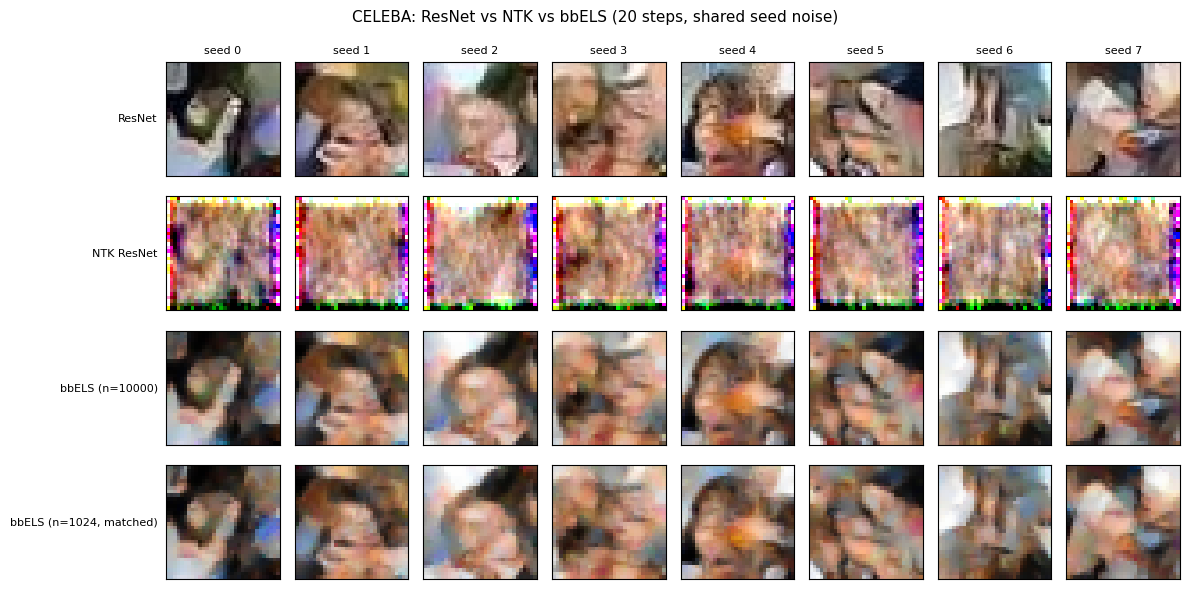

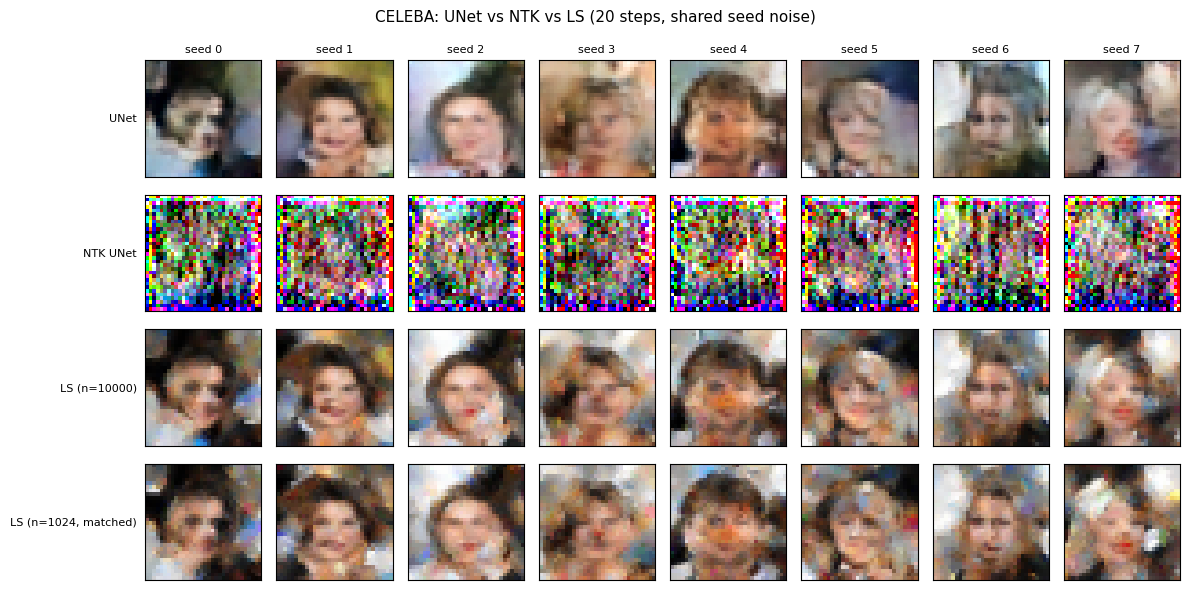

In [4]:
for name, art in artifacts.items():
    plot_sample_grid(art)
    plt.show()

## Pointwise score agreement

The samples answer "do these look alike"; this answers "are these the same function". Every model's $\varepsilon$-prediction is evaluated on **one shared batch** of noised held-out images at each noise level, and the pairwise cosine similarity is plotted against the reverse step.

This is the sharper test of the question: two score functions can produce visually similar samples while disagreeing pointwise, and can agree at high noise (where everything is close to the Gaussian score) while diverging as structure appears.

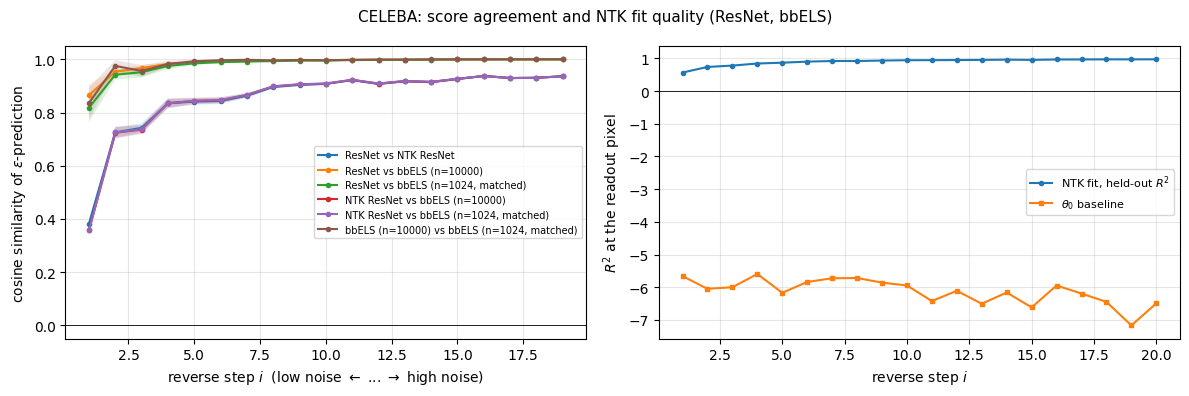

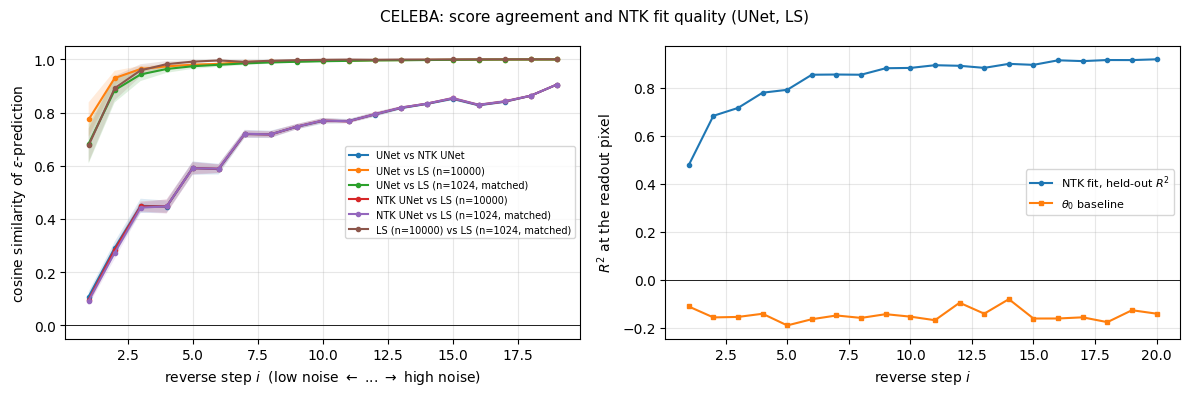

In [5]:
def plot_agreement(art):
    steps = np.asarray(art["agreement_steps"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for pair, vals in art["agreement"].items():
        v = vals.numpy()  # (n_steps, n_images)
        m, s = v.mean(1), v.std(1)
        label = " vs ".join(art["labels"][p] for p in pair.split("|"))
        axes[0].plot(steps, m, marker="o", ms=3, label=label)
        axes[0].fill_between(steps, m - s, m + s, alpha=0.15)

    axes[0].set_xlabel("reverse step $i$  (low noise $\\leftarrow$ ... $\\rightarrow$ high noise)")
    axes[0].set_ylabel("cosine similarity of $\\varepsilon$-prediction")
    axes[0].axhline(0.0, color="k", lw=0.6)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(fontsize=7)

    diag = art["ntk_diagnostics"]
    ds = sorted(diag)
    axes[1].plot(ds, [diag[i]["holdout_r2"] for i in ds], marker="o", ms=3,
                 label="NTK fit, held-out $R^2$")
    axes[1].plot(ds, [diag[i]["holdout_r2_theta0"] for i in ds], marker="s", ms=3,
                 label=r"$\theta_0$ baseline")
    axes[1].axhline(0.0, color="k", lw=0.6)
    axes[1].set_xlabel("reverse step $i$")
    axes[1].set_ylabel("$R^2$ at the readout pixel")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend(fontsize=8)

    name = art["metadata"]["name"].upper()
    fig.suptitle(f"{name}: score agreement and NTK fit quality "
                 f"({art['network_label']}, {art['score_module_type']})", fontsize=11)
    fig.tight_layout()
    return fig


for name, art in artifacts.items():
    plot_agreement(art)
    plt.show()

## NTK fit diagnostics

Sanity checks on the regression itself, per noise level:

- `train_r2` &mdash; how well the ridge solution reproduces its own training targets. Near 1 means the kernel system was solved; well below 1 means the ridge is dominating.
- `holdout_r2` &mdash; the number that actually matters. If this sits near 0, the NTK model has not learned a useful denoiser at that noise level and its samples should not be over-interpreted. `holdout_r2_theta0` is the same quantity for the untrained $\theta_0$, as a floor.
- `train_reconstruction_rel` &mdash; end-to-end check that applying $d\theta$ through the JVP actually reproduces the kernel system's own fitted values $\Theta a$ on the training readouts. This is the diagnostic that catches a mismatch between how the gradient rows were flattened and how $d\theta$ is unflattened, and it is also where finite gradient precision shows up: it is largest at the low-noise steps, where the Gram is most ill-conditioned and the ridge coefficients are largest.
- `delta_norm` &mdash; $\lVert d\theta \rVert$. A very large value means the kernel system was ill-conditioned and the fit is extrapolating hard.

In [6]:
for name, art in artifacts.items():
    diag = art["ntk_diagnostics"]
    print(f"=== {name} ===")
    print(f"{'step':>4} {'beta_t':>8} {'train_R2':>9} {'hold_R2':>9} {'R2(th0)':>9} "
          f"{'|dtheta|':>10} {'recon_rel':>10} {'k(local)':>8}")
    for i in sorted(diag):
        d = diag[i]
        k = art["scales"][i] if i < len(art["scales"]) else "-"
        print(f"{i:>4} {d['beta_t']:>8.4f} {d['train_r2']:>9.4f} "
              f"{d.get('holdout_r2', float('nan')):>9.4f} {d.get('holdout_r2_theta0', float('nan')):>9.4f} "
              f"{d['delta_norm']:>10.3e} {d.get('train_reconstruction_rel', float('nan')):>10.2e} {k:>8}")
    print()

=== celeba_ResNet_bbELS_N1024 ===
step   beta_t  train_R2   hold_R2   R2(th0)   |dtheta|  recon_rel k(local)
   1   0.0061    0.9826    0.5641   -5.6596  2.060e+00   1.24e-02        3
   2   0.0241    0.9783    0.7361   -6.0480  7.571e-01   5.80e-03        3
   3   0.0537    0.9884    0.7774   -6.0004  6.174e-01   5.36e-03        5
   4   0.0940    0.9925    0.8415   -5.5946  5.282e-01   3.77e-03        5
   5   0.1442    0.9945    0.8660   -6.1708  4.714e-01   3.54e-03        5
   6   0.2031    0.9961    0.8988   -5.8384  4.259e-01   2.43e-03        5
   7   0.2691    0.9973    0.9177   -5.7264  3.871e-01   3.78e-03        5
   8   0.3408    0.9979    0.9181   -5.7184  3.678e-01   4.68e-03        7
   9   0.4162    0.9984    0.9315   -5.8587  3.467e-01   3.04e-03        7
  10   0.4938    0.9987    0.9421   -5.9462  3.301e-01   2.67e-03        9
  11   0.5714    1.0000    0.9432   -6.4226  4.196e-01   1.95e-03        9
  12   0.6474    0.9992    0.9476   -6.1096  3.043e-01   1.69e-03 